# Team11: SAND reward budget EDA

The dashboard helps a game studio's campaign operations manager size a SAND reward pool within a fixed USD budget. This notebook uses Pandas and Matplotlib to check the source and select the few measures that support that decision.

**Main findings:** the 1,322 daily observations form a complete calendar. Large price changes make a fixed token reward expensive to promise in advance. Price and market trading volume vary across historical periods, so a recent date filter is more useful for weekly planning than a full-history chart alone.

## 1. Source and business question

- **Kaggle dataset:** [Cryptocoins Historical Prices - CoinGecko](https://www.kaggle.com/datasets/sudalairajkumar/cryptocurrency-historical-prices-coingecko).
- **File:** `data/the-sandbox.csv`, 104,138 bytes. We use the complete CSV without sampling.
- **Period:** 2020-08-14 to 2024-03-27. Each row is one daily SAND market observation from CoinGecko. These are historical market records, not synthetic game transactions.
- **Game context:** [The Sandbox describes SAND](https://docs.sandbox.game/en/owners/sand) as the ecosystem's native token. The game studio and its reward campaign are an assumed business scenario, not entities observed in this CSV.
- **Timing:** CoinGecko's [historical market chart documentation](https://docs.coingecko.com/reference/coins-id-market-chart) describes daily historical points at 00:00 UTC. `price` is a daily snapshot, not an exchange closing price or an intraday high/low.

| Field | Meaning used in this project |
| --- | --- |
| `date` | Observation date |
| `price` | USD per SAND at the daily observation |
| `total_volume` | CoinGecko's market-aggregated trading volume in USD, reported with the observation |
| `market_cap` | Market capitalization in USD |
| `coin_name` | Token identifier, fixed as `the-sandbox` |

**Decision:** if SAND's price has moved sharply over seven calendar days, the operations manager revises the token quantity before approving the next reward campaign. A fixed USD pool buys `budget / price` SAND at the reference price. This estimate excludes fees and execution slippage. Trading volume provides market activity context, not game revenue or an executable liquidity quote.

In [1]:
from pathlib import Path
import math
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display

# Works when opened from the repository root or the notebooks directory.
repo_root = next(
    (p for p in (Path.cwd(), Path.cwd().parent)
     if (p / "data" / "the-sandbox.csv").is_file()),
    None,
)
if repo_root is None:
    raise FileNotFoundError("Open this notebook from the repository root or notebooks directory.")
data_path = repo_root / "data" / "the-sandbox.csv"
raw = pd.read_csv(data_path)

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.18,
    "font.size": 10,
})
PRICE_COLOR = "#2563EB"
VOLUME_COLOR = "#0891B2"
millions = FuncFormatter(lambda value, _: f"${value / 1_000_000:,.0f}M")

print(f"Source shape: {raw.shape[0]:,} rows x {raw.shape[1]} columns")
print(f"CSV size: {data_path.stat().st_size:,} bytes")
display(raw.head())
display(pd.DataFrame({"source_dtype": raw.dtypes.astype(str),
                      "missing_values": raw.isna().sum()}))

Source shape: 1,322 rows x 5 columns
CSV size: 104,138 bytes


,date,price,total_volume,market_cap,coin_name
0,2020-08-14,0.080920,3.841302e+07,0.000000e+00,the-sandbox
1,2020-08-15,0.066403,1.410560e+08,0.000000e+00,the-sandbox
2,2020-08-16,0.050784,4.315041e+07,0.000000e+00,the-sandbox
3,2020-08-17,0.061080,3.370087e+07,3.276463e+07,the-sandbox
4,2020-08-18,0.054974,1.621430e+07,7.171054e+07,the-sandbox


,source_dtype,missing_values
date,str,0
price,float64,0
total_volume,float64,0
market_cap,float64,0
coin_name,str,0


## 2. Data quality and preparation

Parse dates and numeric columns explicitly. Check uniqueness, calendar coverage, finite values, and the denominators needed for budget conversion. A missing or nonpositive price must remain unavailable rather than become zero or a carried-forward quote. A future refresh with duplicate dates needs investigation before the app chooses a price.

In [2]:
required = {"date", "price", "total_volume", "market_cap", "coin_name"}
assert set(raw.columns) == required, "The CSV schema has changed."

df = raw.copy()
df["date"] = pd.to_datetime(df["date"], errors="coerce")
numeric_columns = ["price", "total_volume", "market_cap"]
for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

assert df["date"].notna().all(), "Invalid or missing dates require source review."
assert df[numeric_columns].notna().all().all(), "Missing numeric values require source review."
assert df[numeric_columns].map(math.isfinite).all().all(), "Nonfinite numeric values require source review."
assert df["price"].gt(0).all(), "Budget conversion requires a positive price."
assert df["total_volume"].ge(0).all(), "Negative reported trading volume is invalid."
assert df["market_cap"].ge(0).all(), "Negative market capitalization is invalid."
assert not df["date"].duplicated().any(), "Resolve duplicate observation dates before analysis."
assert df["coin_name"].eq("the-sandbox").all(), "Unexpected token identifier."

df = df.sort_values("date").reset_index(drop=True)
calendar_days = pd.date_range(df["date"].min(), df["date"].max(), freq="D")
missing_dates = calendar_days.difference(pd.DatetimeIndex(df["date"]))
checks = pd.Series({
    "source_rows": len(raw),
    "source_columns": len(raw.columns),
    "missing_source_cells": int(raw.isna().sum().sum()),
    "duplicate_source_rows": int(raw.duplicated().sum()),
    "duplicate_dates": int(df["date"].duplicated().sum()),
    "expected_calendar_days": len(calendar_days),
    "missing_calendar_days": len(missing_dates),
    "nonpositive_prices": int(df["price"].le(0).sum()),
    "zero_reported_volumes": int(df["total_volume"].eq(0).sum()),
    "zero_market_caps": int(df["market_cap"].eq(0).sum()),
}, name="count")
display(checks.to_frame())
print(f"Data period: {df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
display(df.dtypes.astype(str).rename("prepared_dtype").to_frame())
display(df.loc[df["market_cap"].eq(0), ["date", "price", "market_cap"]])

,count
source_rows,1322
source_columns,5
missing_source_cells,0
duplicate_source_rows,0
duplicate_dates,0
expected_calendar_days,1322
missing_calendar_days,0
nonpositive_prices,0
zero_reported_volumes,0
zero_market_caps,3


Data period: 2020-08-14 to 2024-03-27


,prepared_dtype
date,datetime64[us]
price,float64
total_volume,float64
market_cap,float64
coin_name,str


,date,price,market_cap
0,2020-08-14,0.080920,0.0
1,2020-08-15,0.066403,0.0
2,2020-08-16,0.050784,0.0


There are **no missing source cells, duplicate rows, duplicate dates, or missing calendar days**. All prices and volumes are positive. No observations need removal or imputation.

Market capitalization is **zero on the first three dates**, even though the price and volume are positive. The file provides no explanation. We preserve the source values and avoid interpreting them as a collapse in token value. Market capitalization is excluded from the app because it does not enter the reward budget calculation.

In [3]:
# Reindex before calculating changes: a missing date must not turn a multi-day
# change into a daily return. No filling or interpolation is applied.
calendar = df.set_index("date").reindex(calendar_days)
calendar.index.name = "date"
calendar["daily_return_pct"] = calendar["price"].pct_change(fill_method=None) * 100
calendar["seven_day_change_pct"] = (
    calendar["price"] / calendar["price"].shift(7) - 1
) * 100
calendar["abs_daily_return_pct"] = calendar["daily_return_pct"].abs()
analysis = calendar.loc[df["date"]].copy()

# The first day has no earlier quote. The first seven days have no week-earlier quote.
print("Unavailable daily returns:", int(analysis["daily_return_pct"].isna().sum()))
print("Unavailable seven-day changes:", int(analysis["seven_day_change_pct"].isna().sum()))
display(analysis[["price", "total_volume", "market_cap", "daily_return_pct"]]
        .describe(percentiles=[0.01, 0.25, 0.50, 0.75, 0.99]).round(4))

Unavailable daily returns: 1
Unavailable seven-day changes: 7


,price,total_volume,market_cap,daily_return_pct
count,1322.0000,1.322000e+03,1.322000e+03,1321.0000
mean,1.0228,2.869735e+08,1.219028e+09,0.4593
std,1.3212,5.776695e+08,1.251983e+09,8.0510
min,0.0309,2.094053e+06,0.000000e+00,-37.3380
1%,0.0365,3.879962e+06,2.176568e+07,-16.7447
25%,0.3671,5.877710e+07,4.568628e+08,-3.2397
50%,0.5862,1.260176e+08,9.019935e+08,-0.0944
75%,0.8823,2.979130e+08,1.370743e+09,3.0691
99%,6.0299,2.868715e+09,5.523527e+09,29.0830
max,7.5136,8.705030e+09,6.803492e+09,104.0219


## 3. Distributions

Use the original USD price scale, a logarithmic transformation for the wide volume range, and percentage changes for day-to-day movement. All dates remain in the analysis.

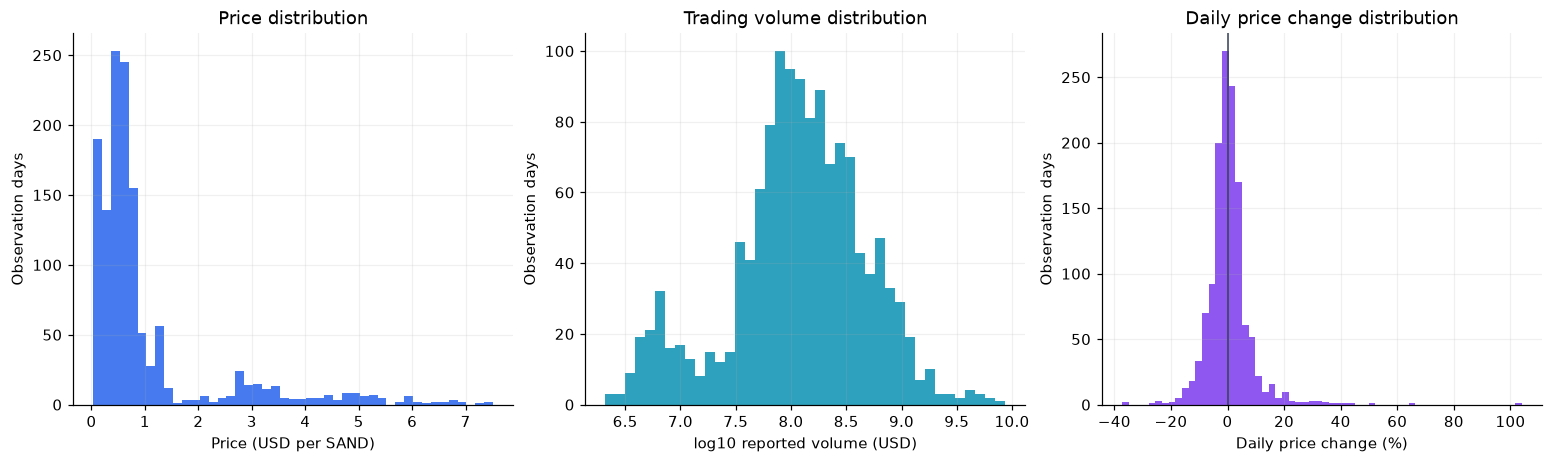

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.1), constrained_layout=True)
axes[0].hist(analysis["price"], bins=45, color=PRICE_COLOR, alpha=0.85)
axes[0].set(title="Price distribution", xlabel="Price (USD per SAND)", ylabel="Observation days")
axes[1].hist(analysis["total_volume"].map(math.log10), bins=40,
             color=VOLUME_COLOR, alpha=0.85)
axes[1].set(title="Trading volume distribution", xlabel="log10 reported volume (USD)",
             ylabel="Observation days")
axes[2].hist(analysis["daily_return_pct"].dropna(), bins=60,
             color="#7C3AED", alpha=0.85)
axes[2].axvline(0, color="#334155", linewidth=1)
axes[2].set(title="Daily price change distribution", xlabel="Daily price change (%)",
             ylabel="Observation days")
plt.show()

Price and volume are strongly right-skewed. The median price is **\$0.5862**, while the maximum daily snapshot is **\$7.5136**. Median reported trading volume is **\$126.0 million**, compared with a maximum of **\$8.705 billion**. Large historical values would compress a recent period on a full-history linear chart, so the app starts with the latest 90 observation days and allows the user to widen the date range.

Daily price changes have long tails: **139 of 1,321 available changes exceed 10% in absolute value**. The distribution supports reviewing reward quantities before approval. It does not establish a probability model for future prices.

## 4. Historical changes

Compare annual summaries and view price with volume on separate axes. The 2020 and 2024 samples are partial years, so annual totals would be misleading.

,observation_days,median_price_usd,max_price_usd,median_reported_volume_usd,daily_change_std_pct
year,,,,,
2020,140,0.0448,0.0809,6.830954e+06,8.4446
2021,365,0.6120,7.5136,1.219653e+08,12.2639
2022,365,1.2884,6.0135,3.106376e+08,5.6492
2023,365,0.4524,0.9109,9.091673e+07,4.1537
2024,87,0.5104,0.7923,1.166032e+08,4.3904


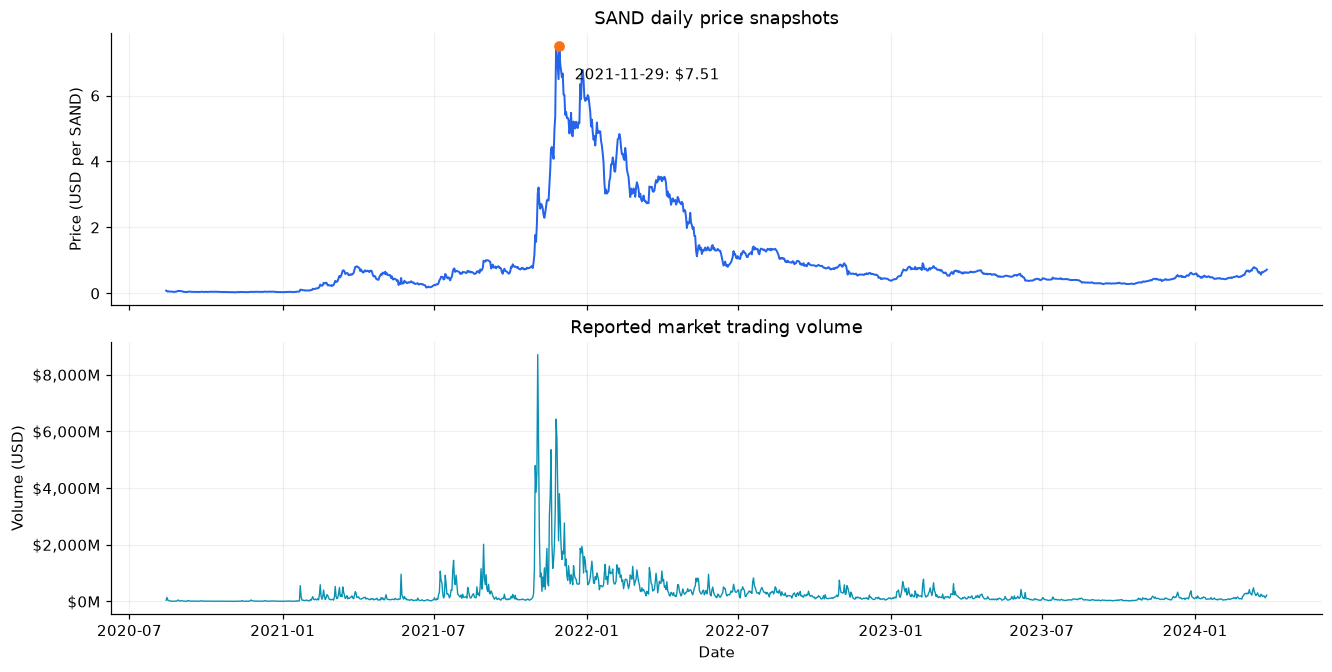

In [5]:
yearly = analysis.groupby(analysis.index.year).agg(
    observation_days=("price", "size"),
    median_price_usd=("price", "median"),
    max_price_usd=("price", "max"),
    median_reported_volume_usd=("total_volume", "median"),
    daily_change_std_pct=("daily_return_pct", "std"),
)
yearly.index.name = "year"
display(yearly.round(4))

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True, constrained_layout=True)
axes[0].plot(analysis.index, analysis["price"], color=PRICE_COLOR, linewidth=1.3)
axes[0].set(title="SAND daily price snapshots", ylabel="Price (USD per SAND)")
peak_date = analysis["price"].idxmax()
axes[0].scatter([peak_date], [analysis.loc[peak_date, "price"]], color="#F97316", zorder=3)
axes[0].annotate(f"{peak_date:%Y-%m-%d}: ${analysis.loc[peak_date, 'price']:.2f}",
                 xy=(peak_date, analysis.loc[peak_date, "price"]),
                 xytext=(10, -22), textcoords="offset points")
axes[1].plot(analysis.index, analysis["total_volume"], color=VOLUME_COLOR, linewidth=0.9)
axes[1].yaxis.set_major_formatter(millions)
axes[1].set(title="Reported market trading volume", ylabel="Volume (USD)", xlabel="Date")
plt.show()

The daily snapshot reaches its sample maximum on **2021-11-29**. Median price rises from **\$0.6120 in 2021** to **\$1.2884 in 2022**, then falls to **\$0.4524 in 2023**. Median reported volume also differs substantially across those years. These are descriptive changes in the sample. The CSV has no event or campaign records with which to attribute causes.

This supports two app charts: **price** explains the reference conversion rate and **reported trading volume** supplies market activity context. They use the same selected dates but separate scales. A date filter lets the manager focus on the upcoming campaign's planning context without losing access to the larger historical range.

## 5. Relationships

Examine price versus volume, and absolute daily price change versus volume. Correlations describe historical co-movement. They do not show that volume causes price changes or that the studio can trade a reward pool without slippage.

,price,total_volume,market_cap,daily_return_pct,abs_daily_return_pct
price,1.0000,0.6337,0.9717,0.0147,0.0313
total_volume,0.6337,1.0000,0.5861,0.2449,0.3206
market_cap,0.9717,0.5861,1.0000,-0.0039,-0.0317
daily_return_pct,0.0147,0.2449,-0.0039,1.0000,0.4527
abs_daily_return_pct,0.0313,0.3206,-0.0317,0.4527,1.0000


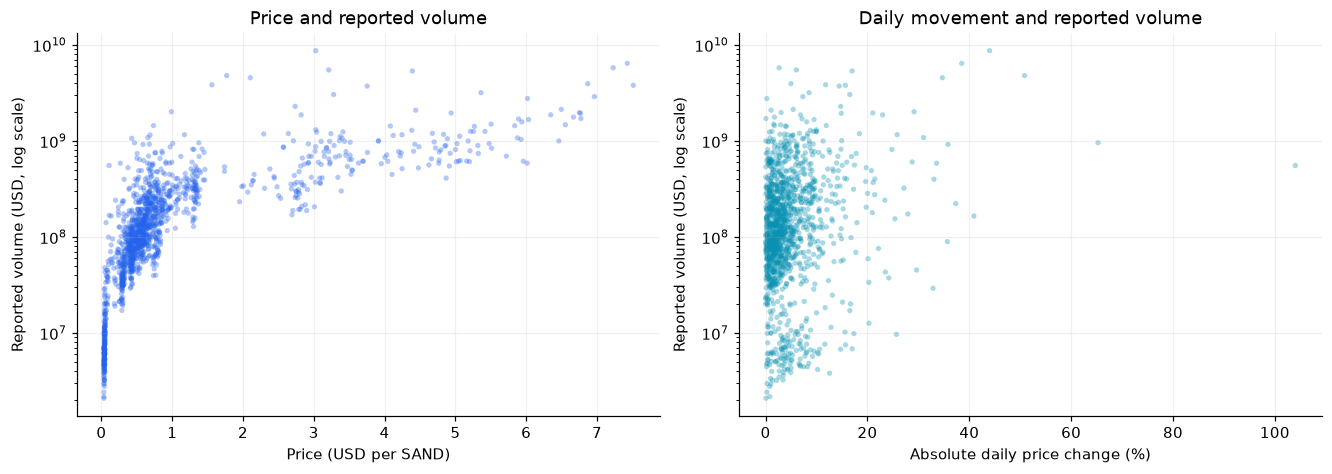

,price_volume_pearson_r
date,
2020,0.5536
2021,0.6428
2022,0.7495
2023,0.6799
2024,0.8463


In [6]:
relationship_columns = ["price", "total_volume", "market_cap", "daily_return_pct", "abs_daily_return_pct"]
display(analysis[relationship_columns].corr().round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)
axes[0].scatter(analysis["price"], analysis["total_volume"],
                s=12, alpha=0.35, color=PRICE_COLOR, edgecolors="none")
axes[0].set_yscale("log")
axes[0].set(title="Price and reported volume", xlabel="Price (USD per SAND)",
             ylabel="Reported volume (USD, log scale)")
valid_returns = analysis.dropna(subset=["daily_return_pct"])
axes[1].scatter(valid_returns["abs_daily_return_pct"], valid_returns["total_volume"],
                s=12, alpha=0.35, color=VOLUME_COLOR, edgecolors="none")
axes[1].set_yscale("log")
axes[1].set(title="Daily movement and reported volume", xlabel="Absolute daily price change (%)",
             ylabel="Reported volume (USD, log scale)")
plt.show()

# Separate annual correlations help expose differences hidden by a pooled statistic.
annual_price_volume = analysis.groupby(analysis.index.year).apply(
    lambda year: year["price"].corr(year["total_volume"])
).rename("price_volume_pearson_r")
display(annual_price_volume.round(4).to_frame())

Across the full sample, price and volume have Pearson correlation **0.6337**. Reported volume and the absolute daily price change have a smaller positive association of **0.3206**. The scatterplots contain substantial dispersion, and annual correlations vary. A volume spike alone cannot determine the direction of a price move.

Price and market capitalization have correlation **0.9717** in this sample. Market capitalization adds little to this particular budget decision and carries unexplained early zeros. We keep it in the source and this EDA, but leave it off the dashboard.

## 6. Outliers and large moves

The 1.5-times-IQR rule is a diagnostic flag, not a deletion rule. This historical series spans very different price levels. Removing its highest observations would erase the period that most clearly demonstrates the reward budget risk.

In [7]:
outlier_rows = []
for column in ["price", "total_volume"]:
    q1, q3 = analysis[column].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    flagged = analysis[column].lt(lower) | analysis[column].gt(upper)
    outlier_rows.append({"field": column, "lower_fence": lower, "upper_fence": upper,
                         "flagged_days": int(flagged.sum()),
                         "share_of_days_pct": flagged.mean() * 100})
display(pd.DataFrame(outlier_rows).set_index("field").round(4))

largest_moves = analysis.loc[
    analysis["abs_daily_return_pct"].nlargest(5).index,
    ["price", "total_volume", "daily_return_pct"],
].sort_values("daily_return_pct", ascending=False)
display(largest_moves.round(4))
print("Days with an absolute daily change above 10%:",
      int(analysis["abs_daily_return_pct"].gt(10).sum()))
print("Largest fall (%):", round(analysis["daily_return_pct"].min(), 4))
print("Largest rise (%):", round(analysis["daily_return_pct"].max(), 4))

,lower_fence,upper_fence,flagged_days,share_of_days_pct
field,,,,
price,-4.055000e-01,1.655000e+00,192,14.5234
total_volume,-2.999267e+08,6.566168e+08,132,9.9849


,price,total_volume,daily_return_pct
date,,,
2021-01-22,0.1092,5.551080e+08,104.0219
2021-05-23,0.4668,9.571483e+08,65.2815
2021-10-31,1.7697,4.794498e+09,50.8455
2021-11-03,3.0278,8.705030e+09,43.9846
2021-02-06,0.1406,1.653015e+08,40.9000


Days with an absolute daily change above 10%: 139
Largest fall (%): -37.338
Largest rise (%): 104.0219


The IQR rule flags **192 price observations** and **132 volume observations**. They are retained. The largest snapshot-to-snapshot rise is **104.02%**, and the largest fall is **37.34%**. We checked the source's numeric validity and continuity, but the CSV alone cannot independently validate every extreme quote. The dashboard shows the recorded series without clipping or smoothing away these moves, labels the historical period, and offers a date filter.

## 7. Translate the evidence into a small dashboard

Calculate the three proposed headline metrics at the latest available observation. A seven-day change uses the quote exactly seven **calendar days** earlier from the full source, even if that reference day sits outside the chart's selected range. If either quote is unavailable, the app should display `N/A`. The budget input is a planning assumption, not a value observed in the dataset.

In [8]:
example_budget_usd = 1_000.0
end_date = analysis.index.max()
reference_date = end_date - pd.Timedelta(days=7)
end_price = analysis.loc[end_date, "price"]
reference_price = calendar["price"].get(reference_date, float("nan"))
seven_day_change = (
    (end_price / reference_price - 1) * 100
    if pd.notna(reference_price) and reference_price > 0 else float("nan")
)
example_kpis = pd.Series({
    "Selected end-date price (USD per SAND)": end_price,
    "Seven-calendar-day price change (%)": seven_day_change,
    "Estimated SAND for a USD 1,000 budget": example_budget_usd / end_price,
}, name=f"As of {end_date:%Y-%m-%d}")
display(example_kpis.round(4).to_frame())

# An equal USD reward pool buys fewer tokens at a higher reference price.
budget_comparison = pd.DataFrame({
    "reference": ["Sample peak price", "Latest snapshot price"],
    "price_usd": [analysis["price"].max(), end_price],
})
budget_comparison["sand_for_usd_1000"] = example_budget_usd / budget_comparison["price_usd"]
display(budget_comparison.round(4))

,As of 2024-03-27
Selected end-date price (USD per SAND),0.7202
Seven-calendar-day price change (%),26.8979
"Estimated SAND for a USD 1,000 budget",1388.5486


,reference,price_usd,sand_for_usd_1000
0,Sample peak price,7.5136,133.0913
1,Latest snapshot price,0.7202,1388.5486


| App element | Decision supported and EDA evidence |
| --- | --- |
| End-date SAND price | Shows the reference USD cost per token. Historical price varies widely. Label it with its date. |
| Seven-day price change | Flags a move over the manager's weekly planning cycle. Use an exact calendar-day comparison. |
| Estimated SAND for the entered USD budget | Converts a fixed campaign budget into a token quantity. A higher price buys fewer tokens. |
| Price trend | Shows whether the reference price follows a recent rise, fall, or stable period. |
| Reported volume trend | Adds market activity context around large moves. It cannot measure order-book depth or game demand. |
| Date range and USD budget inputs | Match the campaign planning window and the manager's budget. Default to the latest 90 days. |

**Two deliberate omissions:** (1) market capitalization, which has a high association with price and does not determine this reward pool; (2) a daily-return histogram, useful in EDA but less direct than the price trend and seven-day change during a weekly budget review. `coin_name` is constant, so it also needs no selector.

**Page order:** Team11 title and role caption, three headline metrics, the two charts, then source and definitions. The conversion decision receives priority within the first screen.

**Production cadence:** refresh daily after the 00:00 UTC observation becomes available. The manager reviews every Monday and immediately before campaign approval. An illustrative internal rule is to review and reapprove the token quantity when the absolute seven-day price change reaches 10%. This threshold is a proposed business policy, not a statistically optimized trading signal. A delayed quote can make a fixed token commitment exceed its USD budget. The deployed assignment remains a clearly labeled Kaggle snapshot ending 2024-03-27.